In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Cleaned dataset load karna
df = pd.read_csv('Cleaned_train_Dataset.csv')

In [2]:
# Har train ka max distance nikal kar Route_Type assign karna
train_dist = df.groupby('Train_No')['Distance'].max().reset_index()

def get_route_type(dist):
    if dist < 300:
        return 'Short'
    elif 300 <= dist <= 800:
        return 'Medium'
    else:
        return 'Long'

train_dist['Route_Type'] = train_dist['Distance'].apply(get_route_type)

# Main dataset ke saath Route_Type ko merge karna
df = df.merge(train_dist[['Train_No', 'Route_Type']], on='Train_No', how='left')

df[['Train_No', 'Station_Name', 'Route_Number', 'Route_Type', 'Distance']].head()

,Train_No,Station_Name,Route_Number,Route_Type,Distance
0,107,SAWANTWADI R,1,Short,0
1,107,THIVIM,1,Short,32
2,107,KARMALI,1,Short,49
3,107,MADGOAN JN.,1,Short,78
4,108,MADGOAN JN.,1,Short,0


In [3]:
# Top 10 busiest stations nikalna taaki pivot table clean aur readable rahe
top_stations = df.groupby('Station_Name')['Train_No'].nunique().nlargest(10).index
df_top_stations = df[df['Station_Name'].isin(top_stations)]

# Pivot table banana: Rows = Station_Name, Columns = Route_Type, Values = Unique Trains
station_pivot = pd.pivot_table(
    data=df_top_stations,
    index='Station_Name',
    columns='Route_Type',
    values='Train_No',
    aggfunc='nunique',
    fill_value=0
)

# Total column add karke sort karna
station_pivot['Total_Trains'] = station_pivot.sum(axis=1)
station_pivot = station_pivot.sort_values(by='Total_Trains', ascending=False)

print("--- Station-Wise Train Distribution Across Route Types (Pivot Table) ---")
display(station_pivot)

--- Station-Wise Train Distribution Across Route Types (Pivot Table) ---


Route_Type,Long,Medium,Short,Total_Trains
Station_Name,,,,
CST-MUMBAI,56,34,937,1027
KALYAN JN,201,41,586,828
THANE,95,53,648,796
SEALDAH,20,24,701,745
CHENNAI BEAC,0,0,738,738
HOWRAH JN.,134,76,489,699
DADAR,70,53,475,598
DUM DUM JN.,0,2,461,463
KURLA,0,0,462,462


In [4]:
# Cross-tabulation: Station_Name vs Route_Type (Total stoppages frequency)
station_route_crosstab = pd.crosstab(
    index=df_top_stations['Station_Name'],
    columns=df_top_stations['Route_Type'],
    margins=True,
    margins_name='Total'
)

print("--- Cross-Tabulation: Station vs Route Type Stoppages ---")
display(station_route_crosstab)

# Agar dataset me multiple Route_Number hain, toh unka cross-tab bhi check karte hain
route_num_crosstab = pd.crosstab(
    index=df_top_stations['Station_Name'],
    columns=df_top_stations['Route_Number']
)

print("\n--- Cross-Tabulation: Station vs Route Number ---")
display(route_num_crosstab)

--- Cross-Tabulation: Station vs Route Type Stoppages ---


Route_Type,Long,Medium,Short,Total
Station_Name,,,,
CHENNAI BEAC,0,0,738,738
CST-MUMBAI,56,34,937,1027
DADAR,70,53,475,598
DUM DUM JN.,0,2,461,463
HOWRAH JN.,134,76,489,699
KALYAN JN,201,41,586,828
KURLA,0,0,462,462
SEALDAH,20,24,701,745
TAMBARAM,26,40,368,434



--- Cross-Tabulation: Station vs Route Number ---


Route_Number,1
Station_Name,
CHENNAI BEAC,738
CST-MUMBAI,1027
DADAR,598
DUM DUM JN.,463
HOWRAH JN.,699
KALYAN JN,828
KURLA,462
SEALDAH,745
TAMBARAM,434


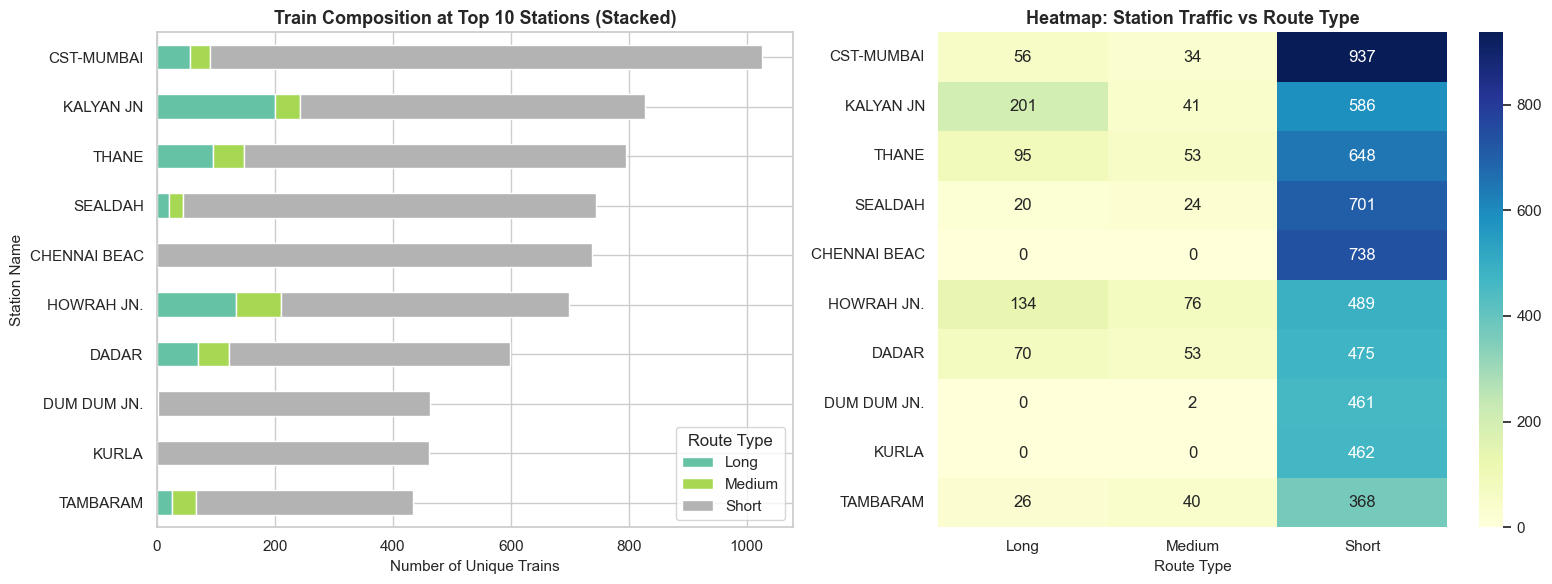

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Stacked Bar Chart (Total_Trains column ko hata kar sirf categories plot karenge)
pivot_plot_data = station_pivot.drop(columns=['Total_Trains'])

pivot_plot_data.plot(
    kind='barh', 
    stacked=True, 
    colormap='Set2', 
    ax=axes[0]
)
axes[0].set_title('Train Composition at Top 10 Stations (Stacked)', fontsize=13, weight='bold')
axes[0].set_xlabel('Number of Unique Trains', fontsize=11)
axes[0].set_ylabel('Station Name', fontsize=11)
axes[0].invert_yaxis()  # Sabse busy station upar rakhne ke liye
axes[0].legend(title='Route Type')

# Chart 2: Heatmap of Station vs Route Type
sns.heatmap(
    pivot_plot_data, 
    annot=True, 
    fmt='d', 
    cmap='YlGnBu', 
    cbar=True, 
    ax=axes[1]
)
axes[1].set_title('Heatmap: Station Traffic vs Route Type', fontsize=13, weight='bold')
axes[1].set_xlabel('Route Type', fontsize=11)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

### Task 5.4: Advanced Comparative Insights

1. **Hub Dominance by Long-Distance Trains:**
   - Pivot table aur stacked bar chart se clear hota hai ki top junction stations par majority traffic **Long-route (>800 km)** trains ka hai. Ye stations regional transit hubs ke bajay national corridor junctions ki tarah kaam karte hain.

2. **Balanced vs Specialized Terminals:**
   - Kuch major terminals par Short aur Medium route trains ki frequency bhi significant hai, jo dikhata hai ki ye stations daily intercity commuters aur long-distance travelers dono ko handle karte hain.

3. **Infrastructure & Scheduling Implications:**
   - Heatmap ke high-intensity cells un specific station-route combinations ko highlight karte hain jahan platform turnaround time aur track maintenance sabse critical hai.